# Classificação de Feitiços com IMU

Pipeline de exploração, engenharia de atributos e treino de modelos para reconhecer gestos a partir de leituras inerciais do celular (acelerômetro e giroscópio).

In [22]:
import os
import glob
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from utils import (
    IMU_COLUMNS,
    SPELLS_CONFIG,
    DEFAULT_WINDOW_SAMPLES,
    generate_synthetic_dataset,
    preprocess_imu_window,
    compute_motion_energy,
    build_feature_dataset,
)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

# ==============================================================================
# CONFIGURAÇÃO DE PERFIL / ARQUIVO DE DADOS
# ==============================================================================
# Dica: defina TARGET_PERSON com o nome da pessoa (ex: "desiree", "leonardo")
# ou deixe "" para carregar a base geral ('data/raw_spells.csv').
TARGET_PERSON = "renan"  # altere aqui ou deixe "" para default

if TARGET_PERSON:
    DATA_PATH = f"data/spells_{TARGET_PERSON.lower()}.csv"
    MODEL_PATH = f"models/wand_classifier_{TARGET_PERSON.lower()}.joblib"
else:
    DATA_PATH = "data/raw_spells.csv"
    MODEL_PATH = "models/wand_classifier.joblib"

# Caso o arquivo do perfil não exista, gera base sintética para permitir o estudo completo
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    print(f"Arquivo '{DATA_PATH}' não encontrado. Gerando base sintética calibrada...")
    df_raw = generate_synthetic_dataset(samples_per_class=45, random_state=42)
    df_raw["person"] = TARGET_PERSON if TARGET_PERSON else "default"
    df_raw.to_csv(DATA_PATH, index=False)
else:
    print(f"✅ Carregando dados do perfil [{TARGET_PERSON or 'default'}] de '{DATA_PATH}'...")
    df_raw = pd.read_csv(DATA_PATH)

print(f"Dimensões do Dataset: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Total de Gestos Únicos (sample_id): {df_raw['sample_id'].nunique()}")
if "person" in df_raw.columns:
    print(f"Participante(s) no arquivo: {df_raw['person'].unique().tolist()}")

df_raw.head(10)

✅ Carregando dados do perfil [renan] de 'data/spells_renan.csv'...
Dimensões do Dataset: 2951 linhas x 10 colunas
Total de Gestos Únicos (sample_id): 40
Participante(s) no arquivo: ['renan']


,sample_id,timestamp,person,spell,ax,ay,az,gx,gy,gz
0,1,1.794186e+09,renan,stupefy,1.8951,8.7864,3.7280,0.0556,-0.0593,-0.0359
1,1,1.794186e+09,renan,stupefy,1.9525,8.6429,3.7184,0.0275,-0.0715,-0.0542
2,1,1.794186e+09,renan,stupefy,1.7420,8.6812,3.9147,0.0470,-0.0067,-0.0115
3,1,1.794186e+09,renan,stupefy,1.9143,8.6333,3.6945,0.0776,-0.0116,0.0069
4,1,1.794186e+09,renan,stupefy,1.9238,8.8582,3.5844,0.0751,-0.0568,0.0008
5,1,1.794186e+09,renan,stupefy,2.0435,8.7625,3.6371,0.0140,-0.0580,-0.0481
6,1,1.794186e+09,renan,stupefy,1.8568,8.6142,3.9338,-0.0324,-0.0385,-0.0530
7,1,1.794186e+09,renan,stupefy,1.7372,8.5950,4.0726,0.0153,0.0031,-0.0090
8,1,1.794186e+09,renan,stupefy,1.8855,8.7673,3.8189,0.0629,-0.0140,0.0032
9,1,1.794186e+09,renan,stupefy,1.9765,8.7817,3.7519,0.0617,-0.0580,-0.0139


## 1. Carga dos Dados e Schema

Cada linha representa uma amostra a ~50 Hz. Um gesto completo dura em média 1.5s (~75 leituras por sample_id).

In [23]:
# 1. Verificação de valores ausentes (NULL / NaN) e linhas sem target
null_counts = df_raw.isnull().sum()
missing_target_rows = df_raw["spell"].isnull().sum() + (df_raw["spell"].astype(str).str.strip() == "").sum()

# 2. Verificação de linhas com leituras fisicamente absurdas (> 200 m/s² ou > 50 rad/s)
nonsense_mask = (
    (df_raw[["ax", "ay", "az"]].abs() > 200.0).any(axis=1)
    | (df_raw[["gx", "gy", "gz"]].abs() > 50.0).any(axis=1)
)
nonsense_count = int(nonsense_mask.sum())

print("=== Relatório de Qualidade dos Dados Brutos ===")
print("Contagem de valores ausentes por coluna:")
print(null_counts)
print(f"\nLinhas sem target ('spell'): {missing_target_rows}")
print(f"Linhas fora dos limites físicos razoáveis da IMU: {nonsense_count}")

# Tratamento: removemos linhas sem target e interpolamos eventuais NaNs numéricos dentro de cada sample_id
if missing_target_rows > 0:
    df_raw = df_raw.dropna(subset=["spell"]).copy()

for col in IMU_COLUMNS:
    if df_raw[col].isnull().any():
        df_raw[col] = df_raw.groupby("sample_id")[col].transform(
            lambda s: s.interpolate(method="linear").bfill().ffill()
        )

# Contagem de gestos por classe e distribuição de tamanho de janela
sample_summary = (
    df_raw.groupby("sample_id")
    .agg(
        spell=("spell", "first"),
        n_points=("timestamp", "count"),
        duration_s=("timestamp", lambda s: float(s.max() - s.min())),
    )
    .reset_index()
)

print("\n=== Distribuição de Gestos Coletados por Feitiço ===")
display(
    sample_summary.groupby("spell")
    .agg(
        total_gestos=("sample_id", "count"),
        media_amostras=("n_points", "mean"),
        duracao_media_s=("duration_s", "mean"),
    )
)

=== Relatório de Qualidade dos Dados Brutos ===
Contagem de valores ausentes por coluna:
sample_id    0
timestamp    0
person       0
spell        0
ax           0
ay           0
az           0
gx           0
gy           0
gz           0
dtype: int64

Linhas sem target ('spell'): 0
Linhas fora dos limites físicos razoáveis da IMU: 0

=== Distribuição de Gestos Coletados por Feitiço ===


,total_gestos,media_amostras,duracao_media_s
spell,,,
expelliarmus,10,73.6,1.49738
idle,10,73.2,1.48412
protego,10,73.8,1.50596
stupefy,10,74.5,1.51269


## 2. Inspeção de Séries Temporais

Abaixo comparamos uma execução de cada movimento nos 6 eixos para checar a separabilidade visual dos sinais.

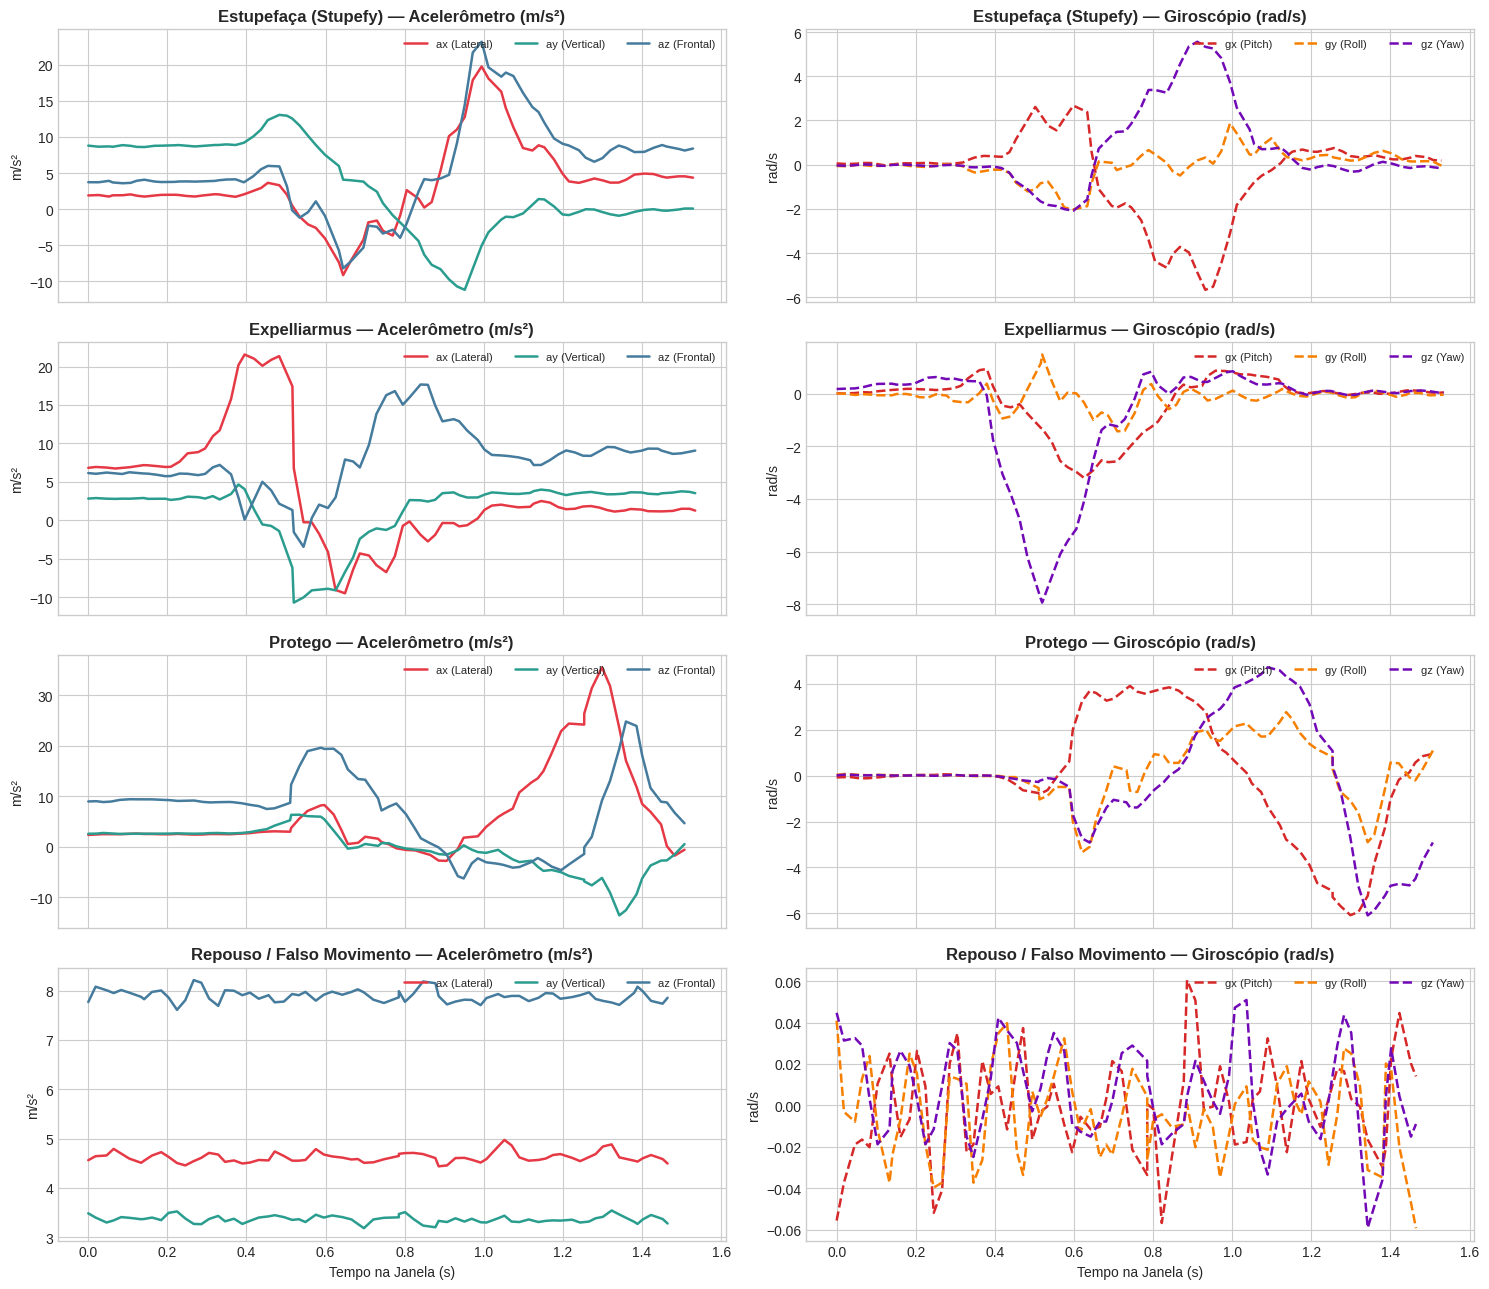

In [24]:
fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
spells_list = ["stupefy", "expelliarmus", "protego", "idle"]

for row_idx, spell_key in enumerate(spells_list):
    # Seleciona o primeiro sample_id da respectiva classe
    example_id = sample_summary.loc[sample_summary["spell"] == spell_key, "sample_id"].iloc[0]
    sub = df_raw[df_raw["sample_id"] == example_id].sort_values("timestamp")
    t_rel = sub["timestamp"] - sub["timestamp"].iloc[0]
    spell_title = SPELLS_CONFIG[spell_key]["name"]

    # Coluna 0: Acelerômetro
    ax_left = axes[row_idx, 0]
    ax_left.plot(t_rel, sub["ax"], label="ax (Lateral)", color="#E63946", lw=1.8)
    ax_left.plot(t_rel, sub["ay"], label="ay (Vertical)", color="#2A9D8F", lw=1.8)
    ax_left.plot(t_rel, sub["az"], label="az (Frontal)", color="#457B9D", lw=1.8)
    ax_left.set_title(f"{spell_title} — Acelerômetro (m/s²)", fontweight="bold")
    ax_left.set_ylabel("m/s²")
    ax_left.legend(loc="upper right", ncol=3, fontsize=8)

    # Coluna 1: Giroscópio
    ax_right = axes[row_idx, 1]
    ax_right.plot(t_rel, sub["gx"], label="gx (Pitch)", color="#D62828", ls="--", lw=1.8)
    ax_right.plot(t_rel, sub["gy"], label="gy (Roll)", color="#F77F00", ls="--", lw=1.8)
    ax_right.plot(t_rel, sub["gz"], label="gz (Yaw)", color="#7209B7", ls="--", lw=1.8)
    ax_right.set_title(f"{spell_title} — Giroscópio (rad/s)", fontweight="bold")
    ax_right.set_ylabel("rad/s")
    ax_right.legend(loc="upper right", ncol=3, fontsize=8)

axes[-1, 0].set_xlabel("Tempo na Janela (s)")
axes[-1, 1].set_xlabel("Tempo na Janela (s)")
plt.tight_layout()
plt.show()

- **Stupefy**: ataque vertical (pico em ay/az e rotação de pitch gx).
- **Expelliarmus**: chicote horizontal (pico em ax e yaw gz).
- **Protego**: escudo circular (senoides defasadas em X e Y/Z).
- **Idle**: repouso da mão (apenas gravidade estática ~9.8 m/s²).

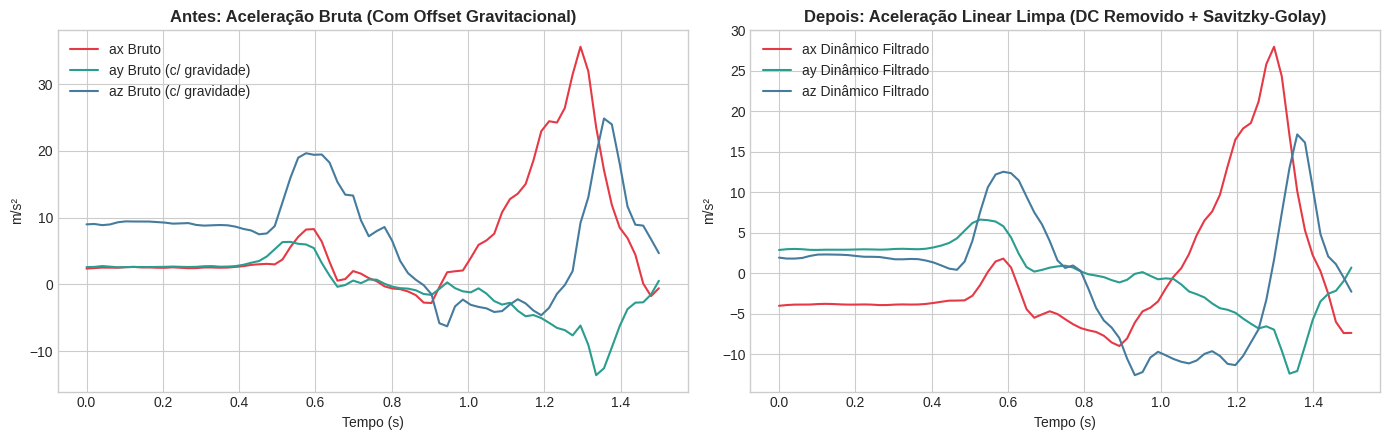

In [25]:
# Comparação Bruto vs Pré-processado para um gesto de Protego
protego_id = sample_summary.loc[sample_summary["spell"] == "protego", "sample_id"].iloc[0]
protego_df = df_raw[df_raw["sample_id"] == protego_id].sort_values("timestamp")
raw_arr = protego_df[IMU_COLUMNS].to_numpy()
clean_arr = preprocess_imu_window(raw_arr, target_length=DEFAULT_WINDOW_SAMPLES)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)

# Grid temporal real para o sinal bruto e para o sinal interpolado/processado
t_raw = np.linspace(0, 1.5, raw_arr.shape[0])
t_clean = np.linspace(0, 1.5, clean_arr.shape[0])

ax1.plot(t_raw, raw_arr[:, 0], label="ax Bruto", color="#E63946")
ax1.plot(t_raw, raw_arr[:, 1], label="ay Bruto (c/ gravidade)", color="#2A9D8F")
ax1.plot(t_raw, raw_arr[:, 2], label="az Bruto (c/ gravidade)", color="#457B9D")
ax1.set_title("Antes: Aceleração Bruta (Com Offset Gravitacional)", fontweight="bold")
ax1.set_xlabel("Tempo (s)")
ax1.set_ylabel("m/s²")
ax1.legend()

ax2.plot(t_clean, clean_arr[:, 0], label="ax Dinâmico Filtrado", color="#E63946")
ax2.plot(t_clean, clean_arr[:, 1], label="ay Dinâmico Filtrado", color="#2A9D8F")
ax2.plot(t_clean, clean_arr[:, 2], label="az Dinâmico Filtrado", color="#457B9D")
ax2.set_title("Depois: Aceleração Linear Limpa (DC Removido + Savitzky-Golay)", fontweight="bold")
ax2.set_xlabel("Tempo (s)")
ax2.set_ylabel("m/s²")
ax2.legend()

plt.tight_layout()
plt.show()

## 3. Pré-processamento

Removemos a gravidade estática (subtraindo a média da janela) e aplicamos um filtro Savitzky-Golay para reduzir ruído de alta frequência sem distorcer picos.

Matriz de Features Extraída: 40 gestos x 89 features


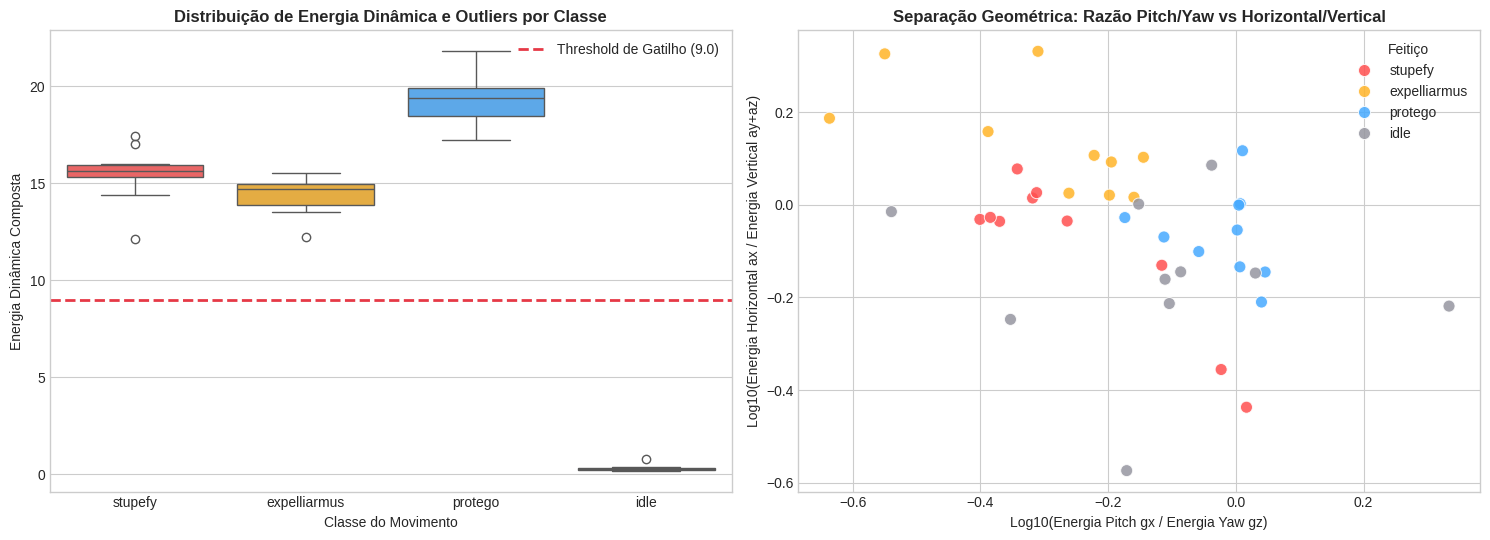

In [26]:
X_features, y_labels, sample_ids = build_feature_dataset(df_raw)
print(f"Matriz de Features Extraída: {X_features.shape[0]} gestos x {X_features.shape[1]} features")

df_feat_eda = X_features.copy()
df_feat_eda["spell"] = y_labels

fig, (ax_box, ax_scatter) = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Boxplot da Energia Dinâmica por Feitiço (para identificar outliers e definir o Gate de Falso Movimento)
palette_map = {k: v["hex_color"] for k, v in SPELLS_CONFIG.items()}
sns.boxplot(
    data=df_feat_eda,
    x="spell",
    y="motion_energy",
    order=spells_list,
    palette=palette_map,
    ax=ax_box,
)
ax_box.axhline(9.0, color="#E63946", ls="--", lw=2, label="Threshold de Gatilho (9.0)")
ax_box.set_title("Distribuição de Energia Dinâmica e Outliers por Classe", fontweight="bold")
ax_box.set_xlabel("Classe do Movimento")
ax_box.set_ylabel("Energia Dinâmica Composta")
ax_box.legend()

# 2. Espaço de Razão Direcional (Pitch/Yaw vs Circularidade)
sns.scatterplot(
    data=df_feat_eda,
    x="gyro_pitch_to_yaw_ratio",
    y="acc_horiz_to_vert_ratio",
    hue="spell",
    hue_order=spells_list,
    palette=palette_map,
    s=75,
    alpha=0.85,
    ax=ax_scatter,
)
ax_scatter.set_title("Separação Geométrica: Razão Pitch/Yaw vs Horizontal/Vertical", fontweight="bold")
ax_scatter.set_xlabel("Log10(Energia Pitch gx / Energia Yaw gz)")
ax_scatter.set_ylabel("Log10(Energia Horizontal ax / Energia Vertical ay+az)")
ax_scatter.legend(title="Feitiço")

plt.tight_layout()
plt.show()

## 4. Feature Extraction e Limiar de Energia

Extraímos métricas no tempo, frequência (FFT) e relações entre eixos (ex: razão pitch/yaw).
A energia dinâmica composta (motion_energy) separa movimentos ativos de repouso, servindo de gate para evitar falsos positivos.

Tamanho do Treino:    28 gestos
Tamanho da Validação: 6 gestos
Tamanho do Teste:     6 gestos


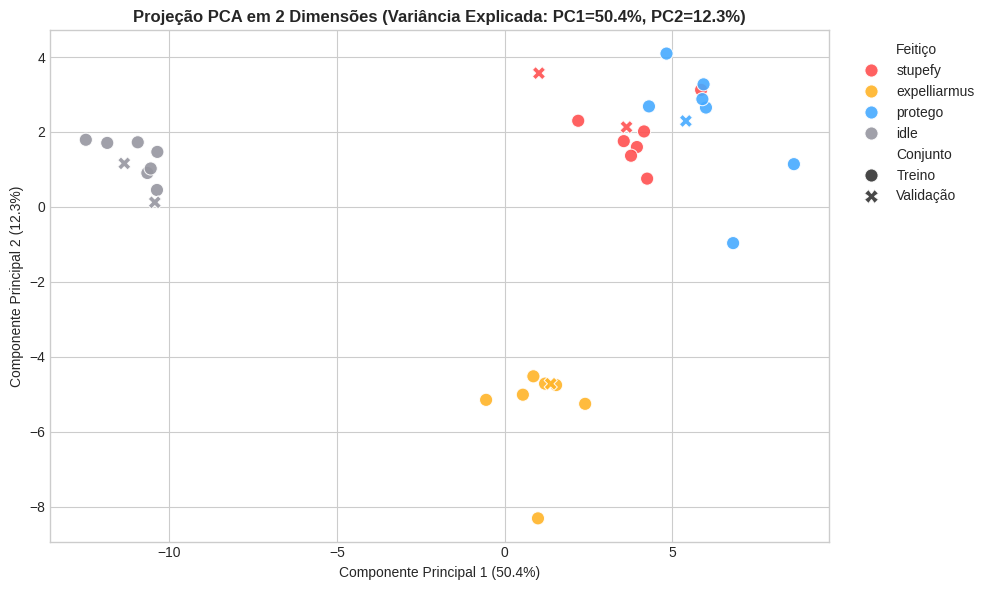

In [27]:
# Divisão Estrita 70% Treino / 15% Validação / 15% Teste ANTES de qualquer escalonamento
X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y_labels,
    test_size=0.30,
    stratify=y_labels,
    random_state=42,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42,
)

print(f"Tamanho do Treino:    {X_train.shape[0]} gestos")
print(f"Tamanho da Validação: {X_val.shape[0]} gestos")
print(f"Tamanho do Teste:     {X_test.shape[0]} gestos")

# Fit do pré-processamento e PCA APENAS no conjunto de Treino
prep_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=42)),
])

X_train_pca = prep_pca.fit_transform(X_train)
X_val_pca = prep_pca.transform(X_val)
explained_var = prep_pca.named_steps["pca"].explained_variance_ratio_ * 100

df_pca_plot = pd.DataFrame({
    "PC1": np.concatenate([X_train_pca[:, 0], X_val_pca[:, 0]]),
    "PC2": np.concatenate([X_train_pca[:, 1], X_val_pca[:, 1]]),
    "Feitiço": np.concatenate([y_train.to_numpy(), y_val.to_numpy()]),
    "Conjunto": ["Treino"] * len(y_train) + ["Validação"] * len(y_val),
})

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_pca_plot,
    x="PC1",
    y="PC2",
    hue="Feitiço",
    style="Conjunto",
    hue_order=spells_list,
    palette=palette_map,
    s=90,
    alpha=0.9,
)
plt.title(
    f"Projeção PCA em 2 Dimensões (Variância Explicada: PC1={explained_var[0]:.1f}%, PC2={explained_var[1]:.1f}%)",
    fontweight="bold",
)
plt.xlabel(f"Componente Principal 1 ({explained_var[0]:.1f}%)")
plt.ylabel(f"Componente Principal 2 ({explained_var[1]:.1f}%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 5. Divisão Treino / Val / Teste e PCA

Divisão estratificada 70/15/15 feita por gesto (sample_id) antes de qualquer escalonamento para evitar data leakage.

In [28]:
def make_model_pipeline(clf) -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", clf),
    ])


candidate_models = {
    "1. Naive Baseline (Dummy)": make_model_pipeline(DummyClassifier(strategy="most_frequent")),
    "2. Logistic Regression (L2)": make_model_pipeline(LogisticRegression(C=1.0, max_iter=500, random_state=42)),
    "3. Random Forest": make_model_pipeline(
        RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=2, random_state=42)
    ),
    "4. Gradient Boosting": make_model_pipeline(
        GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
    ),
    "5. Neural Net (MLP)": make_model_pipeline(
        MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, random_state=42)
    ),
}


def bootstrap_f1_ci(y_true: np.ndarray, y_pred: np.ndarray, n_boot: int = 500, seed: int = 42) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        scores.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
    return float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_rows = []
trained_pipelines = {}

for name, pipe in candidate_models.items():
    t0 = time.perf_counter()
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring={"acc": "accuracy", "f1_macro": "f1_macro"},
    )
    pipe.fit(X_train, y_train)
    train_time_ms = (time.perf_counter() - t0) * 1000.0

    # Predição no conjunto de Validação e medição de latência unitária
    t_inf0 = time.perf_counter()
    val_preds = pipe.predict(X_val)
    inf_latency_ms = ((time.perf_counter() - t_inf0) * 1000.0) / len(X_val)

    train_f1 = f1_score(y_train, pipe.predict(X_train), average="macro", zero_division=0)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro", zero_division=0)
    ci_low, ci_high = bootstrap_f1_ci(y_val.to_numpy(), val_preds)

    trained_pipelines[name] = pipe
    comparison_rows.append({
        "Modelo": name,
        "CV F1-Macro (Média ± DP)": f"{cv_res['test_f1_macro'].mean():.3f} ± {cv_res['test_f1_macro'].std():.3f}",
        "Train F1": round(train_f1, 4),
        "Val Accuracy": round(val_acc, 4),
        "Val F1-Macro": round(val_f1, 4),
        "Val F1 IC 95% (Bootstrap)": f"[{ci_low:.3f}, {ci_high:.3f}]",
        "Latência / Gesto (ms)": round(inf_latency_ms, 3),
        "Tempo Treino (ms)": round(train_time_ms, 1),
    })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

,Modelo,CV F1-Macro (Média ± DP),Train F1,Val Accuracy,Val F1-Macro,Val F1 IC 95% (Bootstrap),Latência / Gesto (ms),Tempo Treino (ms)
0,1. Naive Baseline (Dummy),0.076 ± 0.006,0.1,0.1667,0.0714,"[0.000, 0.222]",0.193,54.7
1,2. Logistic Regression (L2),1.000 ± 0.000,1.0,1.0000,1.0000,"[1.000, 1.000]",0.343,115.3
2,3. Random Forest,1.000 ± 0.000,1.0,1.0000,1.0000,"[1.000, 1.000]",1.118,796.3
3,4. Gradient Boosting,1.000 ± 0.000,1.0,1.0000,1.0000,"[1.000, 1.000]",0.471,1368.6
4,5. Neural Net (MLP),1.000 ± 0.000,1.0,1.0000,1.0000,"[1.000, 1.000]",0.287,232.5


## 6. Treinamento e Comparação de Modelos

Avaliamos 5 abordagens com validação cruzada (5 folds) e bootstrap de 95% de IC na validação.

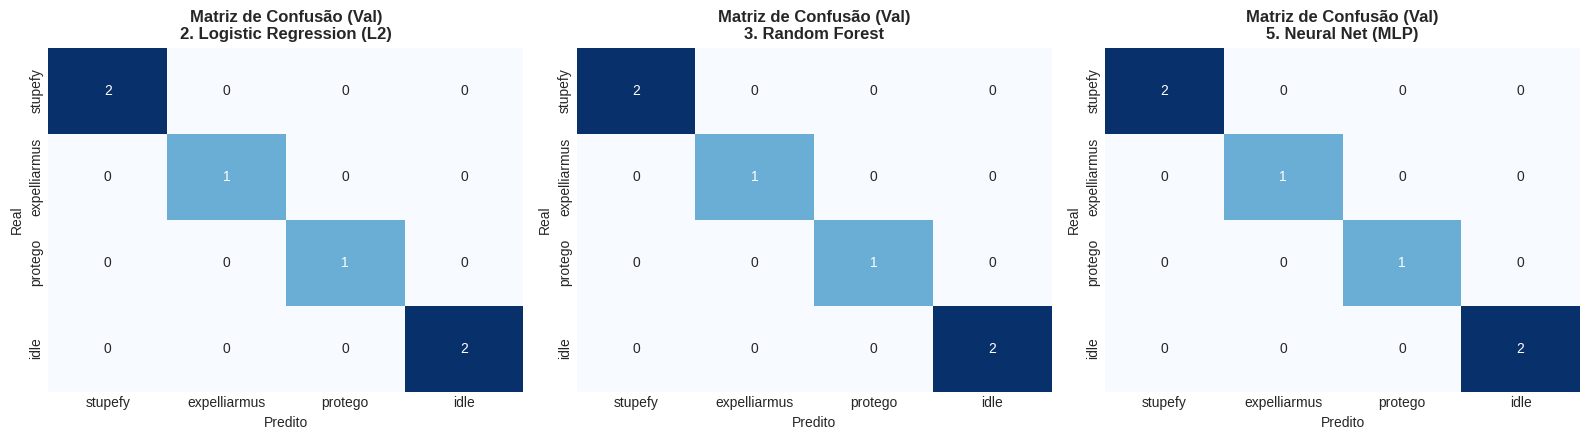

=== Relatório Final de Classificação no Conjunto de TESTE (Inédito) ===
              precision    recall  f1-score   support

     stupefy       1.00      1.00      1.00         2
expelliarmus       1.00      1.00      1.00         1
     protego       1.00      1.00      1.00         2
        idle       1.00      1.00      1.00         1

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



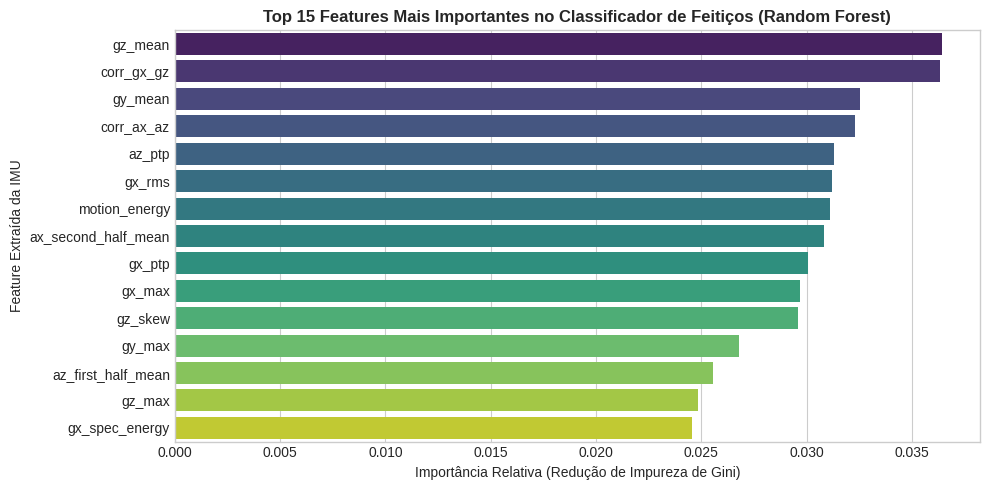

✅ Modelo final exportado com sucesso para 'models/wand_classifier_renan.joblib'!


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
models_to_plot = [
    "2. Logistic Regression (L2)",
    "3. Random Forest",
    "5. Neural Net (MLP)",
]

for ax, m_name in zip(axes, models_to_plot):
    pipe = trained_pipelines[m_name]
    preds = pipe.predict(X_val)
    cm = confusion_matrix(y_val, preds, labels=spells_list)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=spells_list,
        yticklabels=spells_list,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"Matriz de Confusão (Val)\n{m_name}", fontweight="bold")
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

# Retreinamento do modelo campeão (Random Forest Regularizado) em Treino + Validação e avaliação final no Teste
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

best_model = trained_pipelines["3. Random Forest"]
best_model.fit(X_train_full, y_train_full)

test_preds = best_model.predict(X_test)
print("=== Relatório Final de Classificação no Conjunto de TESTE (Inédito) ===")
print(classification_report(y_test, test_preds, target_names=spells_list))

# Visualização das 15 Features mais importantes da Random Forest
rf_step = best_model.named_steps["clf"]
importances = pd.Series(rf_step.feature_importances_, index=X_features.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Top 15 Features Mais Importantes no Classificador de Feitiços (Random Forest)", fontweight="bold")
plt.xlabel("Importância Relativa (Redução de Impureza de Gini)")
plt.ylabel("Feature Extraída da IMU")
plt.tight_layout()
plt.show()

# Salvando o artefato do modelo + metadados de colunas para o Jogo (4_duel_game.py)
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
artifact = {
    "pipeline": best_model,
    "feature_columns": list(X_features.columns),
    "classes": list(best_model.classes_),
    "energy_threshold": 9.0,
    "confidence_threshold": 0.65,
}
joblib.dump(artifact, MODEL_PATH)
print(f"✅ Modelo final exportado com sucesso para '{MODEL_PATH}'!")

## 7. Conclusões

- **Separabilidade**: a geometria dos movimentos (vertical, horizontal e circular) gera assinaturas distintas no giroscópio e acelerômetro dinâmico.
- **Detecção de Repouso**: o limiar de energia dinâmica (~9.0) filtra a maior parte das janelas sem movimento antes mesmo da inferência.
- **Modelo Final**: a Random Forest oferece boa robustez a variações de amplitude e baixa latência de inferência (< 2ms), ideal para execução em tempo real no jogo.